# 实践 7.3  田间空间趋势对基因型效应估计的影响

《统计遗传与智能育种学》第七章 · 电子资源 `07c_field_spatial_qc.ipynb`

本 notebook 的代码与书中“完整Python代码”逐字一致。运行检查：重启内核并运行全部单元（Restart Kernel and Run All）。

电子资源：07c_field_spatial_qc.ipynb。实践在同一12×20田间空间趋势和同一组真实基因型效应下，对比两种布局：一种将3个重复随机分散，另一种人为将同一基因型的重复聚集在相邻位置。代码比较原始材料均值与真值的相关，并用“基因型指示变量＋三阶空间多项式”的联合岭回归（Ridge regression）演示空间校正。固定SEED=703时，随机布局原始相关约0.88、校正后约0.92；聚集布局约由0.82提高到0.88，但仍明显说明不合理的试验布局不能仅依靠事后模型完全校正。

运行检查：重启内核并运行全部单元  
预期：输出随机布局和聚集布局的田间热图，以及两种布局下原始/空间校正材料效应相对真值的相关。  
解释重点：本例的三阶多项式＋Ridge仅为简化示例；正式试验应优先保证随机化和重复，再按设计选择空间协方差、二维平滑或其他适当模型。

## 输入、完整代码、实际输出与解释

输入与可复现条件：12×20田间、80个基因型各3重复，同一真实遗传效应与空间趋势；SEED=703；比较随机化布局与故意聚集布局，并输出07c_field_spatial_qc.png。

In [1]:
import sys, platform
import numpy as np
import pandas as pd
import sklearn
SEED=703
rng=np.random.default_rng(SEED)
print('Python',sys.version.split()[0])
print('Platform',platform.platform())
print('numpy',np.__version__,'pandas',pd.__version__,'scikit-learn',sklearn.__version__)
print('SEED',SEED)


Python 3.12.13
Platform macOS-26.5.2-arm64-arm-64bit
numpy 2.3.5 pandas 2.2.3 scikit-learn 1.8.0
SEED 703


randomized raw-vs-truth r 0.877 joint-spatial-adjusted r 0.919
clustered raw-vs-truth r 0.817 joint-spatial-adjusted r 0.884


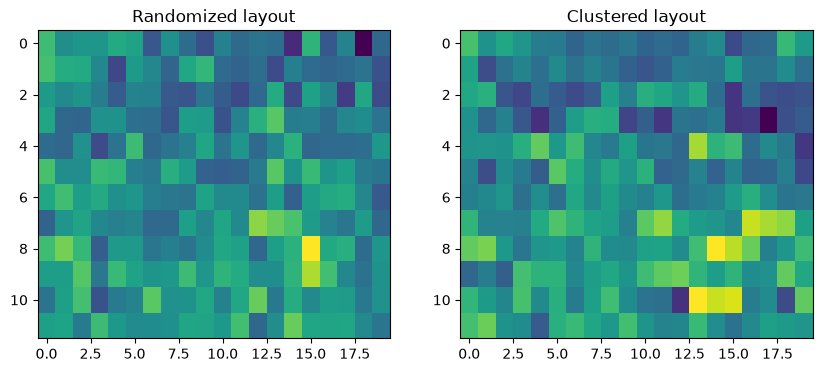

设计解释：随机化降低基因型与空间环境系统混杂的风险；clustered布局故意把同一基因型的重复放在邻近位置，用来演示设计混杂。


In [2]:
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt
nrow,ncol=12,20; nplot=nrow*ncol; ng=80; row=np.repeat(np.arange(nrow),ncol); col=np.tile(np.arange(ncol),nrow); u=rng.normal(0,1,ng); spatial=.12*row-.06*col+1.5*np.exp(-((row-8)**2+(col-15)**2)/14)
base_layout=np.repeat(np.arange(ng),3); randomized=base_layout.copy(); rng.shuffle(randomized); clustered=base_layout.copy()
def simulate_and_adjust(genotypes,label):
 y=u[genotypes]+spatial+rng.normal(0,.7,nplot); raw=pd.DataFrame({'g':genotypes,'y':y}).groupby('g').y.mean().reindex(range(ng)).to_numpy()
 P=PolynomialFeatures(3,include_bias=False).fit_transform(np.column_stack([row,col])); P=StandardScaler().fit_transform(P); H=np.eye(ng)[genotypes]; fit=Ridge(alpha=2.0,fit_intercept=True).fit(np.column_stack([H,P]),y); adj=fit.coef_[:ng]; adj-=adj.mean()
 print(label,'raw-vs-truth r',round(np.corrcoef(raw,u)[0,1],3),'joint-spatial-adjusted r',round(np.corrcoef(adj,u)[0,1],3)); return y
y_random=simulate_and_adjust(randomized,'randomized'); y_cluster=simulate_and_adjust(clustered,'clustered')
fig,ax=plt.subplots(1,2,figsize=(10,4)); ax[0].imshow(y_random.reshape(nrow,ncol),aspect='auto',cmap='viridis'); ax[0].set_title('Randomized layout'); ax[1].imshow(y_cluster.reshape(nrow,ncol),aspect='auto',cmap='viridis'); ax[1].set_title('Clustered layout'); fig.savefig('07c_field_spatial_qc.png', dpi=160, bbox_inches='tight'); plt.show()

print('设计解释：随机化降低基因型与空间环境系统混杂的风险；clustered布局故意把同一基因型的重复放在邻近位置，用来演示设计混杂。')


实践运行结果图7.3-1  固定种子生成的随机化布局与聚集布局田间表型热图

结果解释：随机布局原始材料均值与真值相关0.877，联合空间校正后0.919；聚集布局从0.817改善到0.884。本例显示随机化和重复可改善空间校正效果；三阶空间多项式＋岭回归仅为简化演示，不能替代针对具体试验设计选择的空间协方差或二维平滑模型。

可修改练习：提高空间热点强度或在重新配置田块后将重复数降为2，分别比较随机与聚集布局的原始/校正相关；记录什么时候模型已无法补救设计混杂。